In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Import Basic Libraries

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings("ignore")

# Load Data

In [5]:
data=pd.read_csv('AI_Job_Market_Dataset.csv')
data

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,AI Engineer,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,Machine Learning Engineer,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,Machine Learning Engineer,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,Business Analyst,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,Data Scientist,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10340,10341,Data Engineer,Startup,Technology,USA,Onsite,Entry,2,PhD,1,0,1,0,1,76426,4,2023,Low,4
10341,10342,Data Analyst,Medium,Healthcare,Australia,Hybrid,Entry,10,Master,1,1,0,0,1,61233,9,2024,Medium,6
10342,10343,Machine Learning Engineer,Startup,Education,Germany,Hybrid,Entry,4,PhD,0,0,0,1,0,103681,3,2026,Low,4
10343,10344,Data Engineer,MNC,E-commerce,Canada,Hybrid,Mid,5,PhD,1,1,1,0,0,112895,12,2024,High,9


# Data Exploration

In [6]:
data.sample(10)

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
2432,2433,Data Engineer,Startup,Technology,Germany,Hybrid,Senior,11,Master,0,0,0,1,1,126471,4,2021,High,9
9633,9634,AI Engineer,Startup,Retail,Canada,Remote,Senior,3,Bachelor,0,1,1,0,0,158591,8,2024,Low,2
9425,9426,AI Engineer,Medium,Education,Germany,Remote,Senior,8,Master,1,1,0,1,1,167505,3,2022,Medium,5
9345,9346,Data Scientist,Medium,Technology,Germany,Hybrid,Mid,0,Master,0,1,1,0,0,88079,4,2023,Low,6
9625,9626,Data Engineer,MNC,Finance,UK,Hybrid,Mid,3,Bachelor,1,1,0,1,1,117442,10,2026,High,7
1607,1608,Machine Learning Engineer,Startup,Technology,UK,Remote,Senior,10,PhD,0,1,1,1,0,168991,2,2022,High,8
2155,2156,Data Scientist,MNC,Retail,UK,Remote,Entry,13,PhD,0,0,0,0,1,84665,9,2026,Medium,4
4784,4785,Data Analyst,Enterprise,Education,India,Hybrid,Senior,0,Bachelor,1,0,0,0,1,111794,3,2024,Low,1
8528,8529,Data Engineer,Enterprise,E-commerce,Germany,Remote,Mid,14,PhD,0,1,0,1,0,92726,7,2024,Medium,2
3007,3008,Data Analyst,Enterprise,Education,Germany,Hybrid,Senior,6,Bachelor,0,1,0,0,1,105546,1,2026,Low,2


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   job_id                10345 non-null  int64
 1   job_title             10345 non-null  str  
 2   company_size          10345 non-null  str  
 3   company_industry      10345 non-null  str  
 4   country               10345 non-null  str  
 5   remote_type           10345 non-null  str  
 6   experience_level      10345 non-null  str  
 7   years_experience      10345 non-null  int64
 8   education_level       10345 non-null  str  
 9   skills_python         10345 non-null  int64
 10  skills_sql            10345 non-null  int64
 11  skills_ml             10345 non-null  int64
 12  skills_deep_learning  10345 non-null  int64
 13  skills_cloud          10345 non-null  int64
 14  salary                10345 non-null  int64
 15  job_posting_month     10345 non-null  int64
 16  job_posting_yea

In [8]:
data.isnull().sum()

job_id                  0
job_title               0
company_size            0
company_industry        0
country                 0
remote_type             0
experience_level        0
years_experience        0
education_level         0
skills_python           0
skills_sql              0
skills_ml               0
skills_deep_learning    0
skills_cloud            0
salary                  0
job_posting_month       0
job_posting_year        0
hiring_urgency          0
job_openings            0
dtype: int64

In [9]:
data.describe()

,job_id,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,job_openings
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.00000,10345.000000,10345.000000,10345.00000
mean,5173.000000,6.950507,0.493088,0.503045,0.507878,0.498018,0.511455,113438.22726,6.502465,2023.000387,5.00406
std,2986.488601,4.320054,0.499976,0.500015,0.499962,0.500020,0.499893,31389.20106,3.473441,1.996856,2.58382
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45083.00000,1.000000,2020.000000,1.00000
25%,2587.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,89715.00000,4.000000,2021.000000,3.00000
50%,5173.000000,7.000000,0.000000,1.000000,1.000000,0.000000,1.000000,113082.00000,6.000000,2023.000000,5.00000
75%,7759.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,134894.00000,10.000000,2025.000000,7.00000
max,10345.000000,14.000000,1.000000,1.000000,1.000000,1.000000,1.000000,204143.00000,12.000000,2026.000000,9.00000


# Filling Nulls

In [12]:
data['Gender'].fillna(data['Gender'].mode()[0], inplace=True)
data['Married'].fillna(data['Married'].mode()[0],inplace=True)
data['Dependents'].fillna(data['Dependents'].mode()[0],inplace=True)
data['Self_Employed'].fillna(data['Self_Employed'].mode()[0],inplace=True)
data['LoanAmount'].fillna(data['LoanAmount'].mean(),inplace=True)
data['Loan_Amount_Term'].fillna(data['Loan_Amount_Term'].mean(),inplace=True)
data['Credit_History'].fillna(data['Credit_History'].mean(),inplace=True)

KeyError: 'Gender'

In [11]:
data.isnull().sum()

job_id                  0
job_title               0
company_size            0
company_industry        0
country                 0
remote_type             0
experience_level        0
years_experience        0
education_level         0
skills_python           0
skills_sql              0
skills_ml               0
skills_deep_learning    0
skills_cloud            0
salary                  0
job_posting_month       0
job_posting_year        0
hiring_urgency          0
job_openings            0
dtype: int64

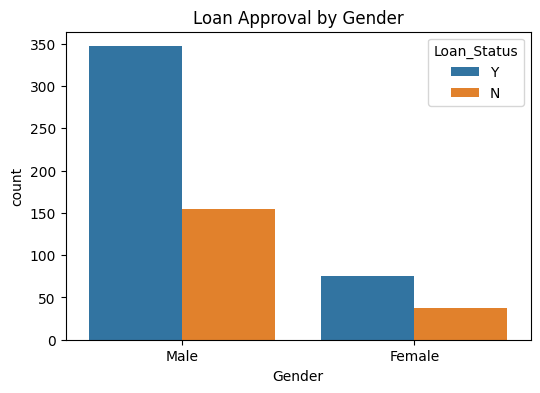

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(x='Gender',hue='Loan_Status',data=data)
plt.title('Loan Approval by Gender')
plt.show()

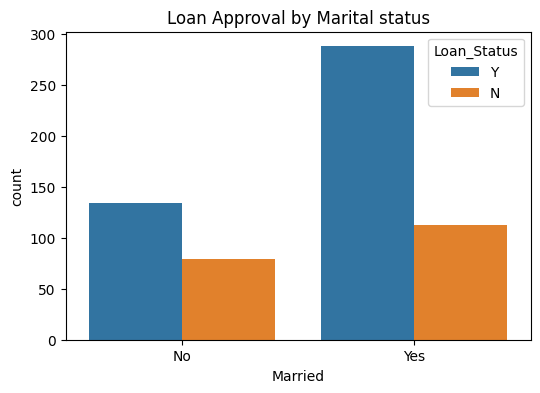

In [11]:
plt.figure(figsize=(6,4))
sns.countplot(x='Married',hue='Loan_Status',data=data)
plt.title('Loan Approval by Marital status')
plt.show()

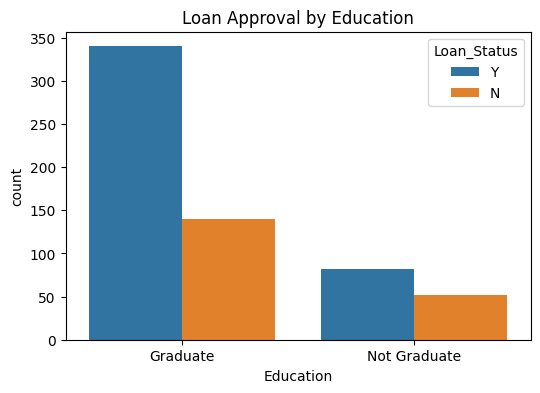

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x='Education',hue='Loan_Status',data=data)
plt.title('Loan Approval by Education')
plt.show()

# Otliers Detection

In [13]:
numerical_cols = ['ApplicantIncome','CoapplicantIncome','LoanAmount']

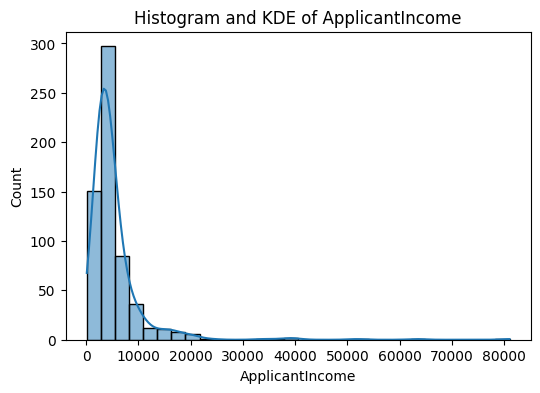

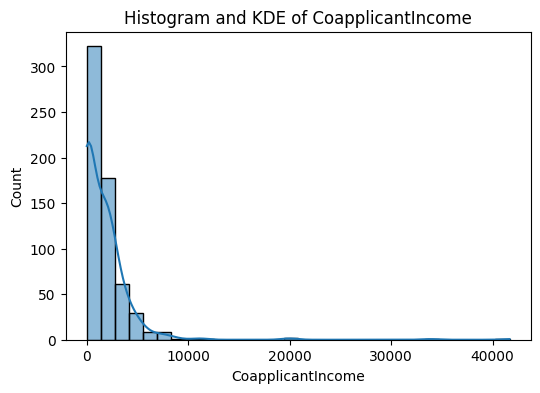

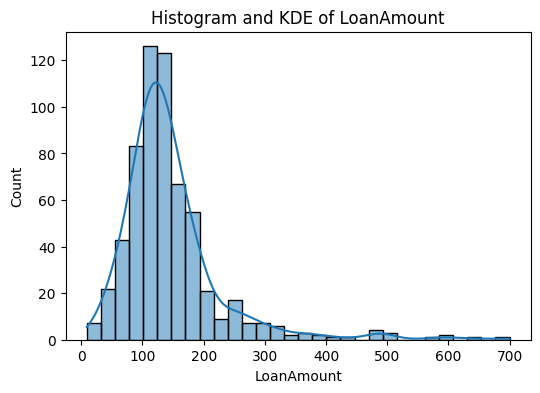

In [14]:
for col in numerical_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(data[col],kde=True,bins=30)
    plt.title(f'Histogram and KDE of {col}')
    plt.show()

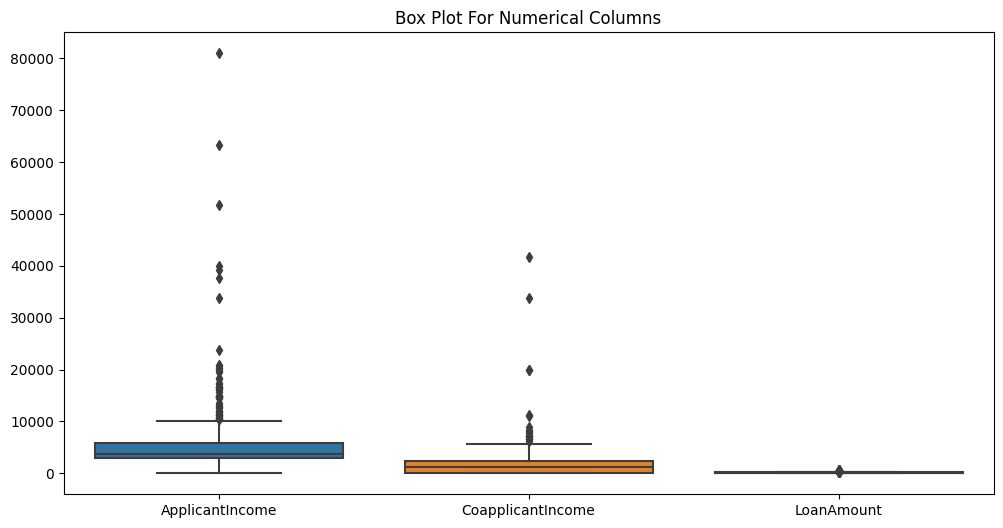

In [15]:
plt.figure(figsize=(12,6))
sns.boxplot(data=data[numerical_cols])
plt.title('Box Plot For Numerical Columns')
plt.show()

In [16]:
for col in numerical_cols :
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    data[col]= np.clip(data[col], lower_bound , upper_bound)

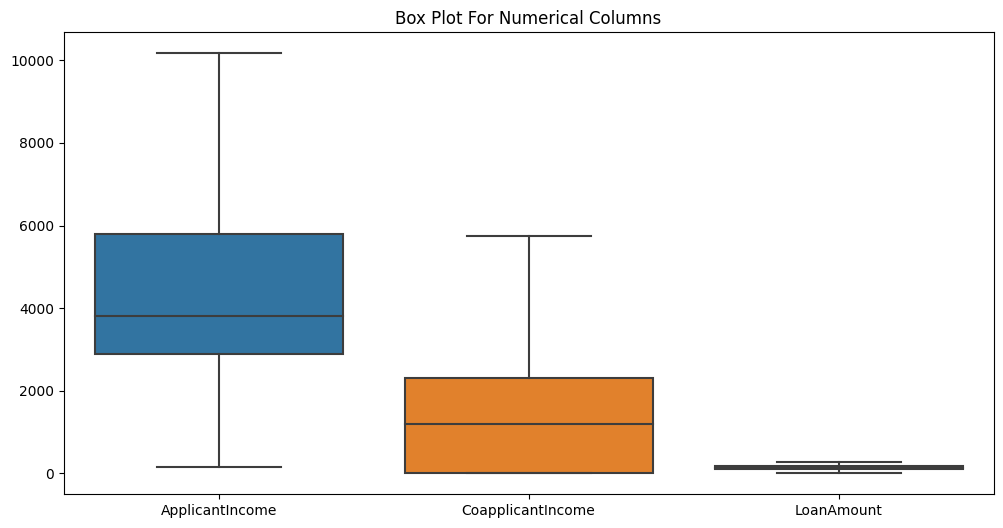

In [17]:
plt.figure(figsize=(12,6))
sns.boxplot(data=data[numerical_cols])
plt.title('Box Plot For Numerical Columns')
plt.show()

In [18]:
le = LabelEncoder()
categorical_cols = ['Gender','Married','Dependents','Education','Self_Employed','Property_Area','Loan_Status']
for col in categorical_cols:
    data[col]= le.fit_transform(data[col])

In [19]:
data.dtypes

Loan_ID               object
Gender                 int64
Married                int64
Dependents             int64
Education              int64
Self_Employed          int64
ApplicantIncome      float64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area          int64
Loan_Status            int64
dtype: object

# Model Creation

In [20]:
X = data.drop (['Loan_ID','Loan_Status'], axis=1)
y= data ['Loan_Status']

In [21]:
X_train, X_test, y_train,y_test = train_test_split(X, y , test_size=0.2 , random_state=42)

In [22]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

In [23]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [24]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 79.67%
